In [1]:
# Standard Library & Paths
import os
import sys
from pathlib import Path
import copy

# Data Science & Math
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# PyTorch & Torchvision
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

# Scikit-learn Metrics
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Hyperparameter Optimization (Optuna)
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

print("All imports loaded successfully!")

All imports loaded successfully!


e:\miniconda\envs\sara-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
BASE_DIR = Path("..").resolve()

if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

PROCESSED_DIR = BASE_DIR / "data" / "cv" / "processed"
OUTPUTS_DIR = BASE_DIR / "outputs"
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f" Running training pipeline on device: {device}")

 Running training pipeline on device: cpu


In [5]:
class CrashDataset(Dataset):
    def __init__(self, csv_file, transform=None):
        self.df = pd.read_csv(csv_file)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = Path(row["frame_path"])

        if not img_path.is_absolute():
            img_path = BASE_DIR / img_path

        image = Image.open(img_path).convert("RGB")
        label = float(row["target"]) 

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.float32), str(row["video_id"])

train_transform = transforms.Compose(
    [
        transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ]
)

val_transform = transforms.Compose(
    [
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ]
)

train_dataset = CrashDataset(PROCESSED_DIR / "train_frames.csv", transform=train_transform)
val_dataset = CrashDataset(PROCESSED_DIR / "val_frames.csv", transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)

print(f" Loaded {len(train_dataset)} training frames and {len(val_dataset)} validation frames.")

 Loaded 1200 training frames and 300 validation frames.


In [6]:
weights = models.MobileNet_V2_Weights.DEFAULT
model = models.mobilenet_v2(weights=weights)

for param in model.parameters():
    param.requires_grad = False

in_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=0.2),
    nn.Linear(in_features, 1)
)

model = model.to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=1e-3)


EPOCHS = 3
print("\n--- Starting Model Training ---")

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct, total = 0, 0
    
    for images, labels, _ in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images).squeeze(1)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        
        preds = (torch.sigmoid(outputs) >= 0.5).float()
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch [{epoch+1}/{EPOCHS}] | Loss: {epoch_loss:.4f} | Frame Accuracy: {epoch_acc*100:.2f}%")



--- Starting Model Training ---
Epoch [1/3] | Loss: 0.6282 | Frame Accuracy: 69.92%
Epoch [2/3] | Loss: 0.5383 | Frame Accuracy: 78.83%
Epoch [3/3] | Loss: 0.4743 | Frame Accuracy: 82.25%



Generated predictions for 10 validation videos.


,video_id,true_label,mean_crash_prob,max_crash_prob,top5_crash_prob,pred_label
0,1347,0,0.418298,0.592146,0.539233,1
1,1367,0,0.622186,0.817443,0.768865,1
2,1648,0,0.227512,0.308286,0.291533,0
3,1794,0,0.386479,0.534263,0.508523,1
4,1898,0,0.208009,0.458832,0.314386,0



=== Official Video-Level Performance Report ===
              precision    recall  f1-score   support

No Crash (0)       0.67      0.40      0.50         5
   Crash (1)       0.57      0.80      0.67         5

    accuracy                           0.60        10
   macro avg       0.62      0.60      0.58        10
weighted avg       0.62      0.60      0.58        10

Confusion matrix plot saved to: C:\Users\98936\Desktop\incident-sentiment-analyzer\outputs\figures\val_video_confusion_matrix.png


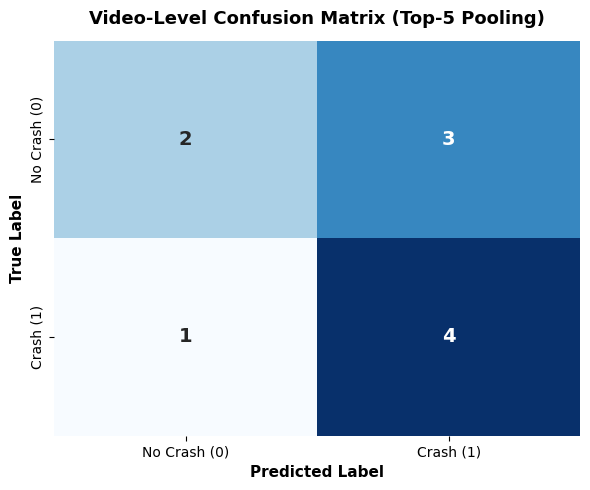


Video predictions saved to: C:\Users\98936\Desktop\incident-sentiment-analyzer\outputs\val_video_predictions.csv
Model checkpoint saved to: C:\Users\98936\Desktop\incident-sentiment-analyzer\outputs\baseline_mobilenet_v2.pth


In [9]:
def top_k_mean(series, k=5):
    return series.nlargest(min(k, len(series))).mean()

model.eval()
val_records = []

with torch.no_grad():
    for images, labels, video_ids in val_loader:
        images = images.to(device)
        outputs = model(images).squeeze(1)
        probs = torch.sigmoid(outputs).cpu().numpy()
        labels_np = labels.numpy()

        for vid, true_lbl, prob in zip(video_ids, labels_np, probs):
            val_records.append(
                {
                    "video_id": vid,
                    "true_label": int(true_lbl),
                    "crash_prob": float(prob),
                }
            )

df_val_frames = pd.DataFrame(val_records)

df_video_preds = (
    df_val_frames.groupby("video_id")
    .agg(
        true_label=("true_label", "first"),
        mean_crash_prob=("crash_prob", "mean"),
        max_crash_prob=("crash_prob", "max"),
        top5_crash_prob=("crash_prob", lambda s: top_k_mean(s, k=5)),
    )
    .reset_index()
)

df_video_preds["pred_label"] = (df_video_preds["top5_crash_prob"] >= 0.5).astype(int)

print(f"\nGenerated predictions for {len(df_video_preds)} validation videos.")
display(df_video_preds.head())

print("\n=== Official Video-Level Performance Report ===")
y_true = df_video_preds["true_label"]
y_pred = df_video_preds["pred_label"]

print(
    classification_report(
        y_true, y_pred, target_names=["No Crash (0)", "Crash (1)"], zero_division=0
    )
)

cm = confusion_matrix(y_true, y_pred)
labels = ["No Crash (0)", "Crash (1)"]

figures_dir = OUTPUTS_DIR / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

cm_save_path = figures_dir / "val_video_confusion_matrix.png"

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=labels,
    yticklabels=labels,
    annot_kws={"size": 14, "weight": "bold"},
)

plt.title(
    "Video-Level Confusion Matrix (Top-5 Pooling)",
    fontsize=13,
    weight="bold",
    pad=12,
)
plt.xlabel("Predicted Label", fontsize=11, weight="bold")
plt.ylabel("True Label", fontsize=11, weight="bold")
plt.tight_layout()

plt.savefig(cm_save_path, dpi=300)
print(f"Confusion matrix plot saved to: {cm_save_path}")
plt.show()

preds_save_path = OUTPUTS_DIR / "val_video_predictions.csv"
df_video_preds.to_csv(preds_save_path, index=False)
print(f"\nVideo predictions saved to: {preds_save_path}")

model_save_path = OUTPUTS_DIR / "baseline_mobilenet_v2.pth"
torch.save(model.state_dict(), model_save_path)
print(f"Model checkpoint saved to: {model_save_path}")

In [10]:
import optuna
from src.cv.engine import train_run

def objective(trial):
    params = dict(
        lr=trial.suggest_float("lr", 1e-4, 5e-3, log=True),
        dropout=trial.suggest_float("dropout", 0.1, 0.5),
        weight_decay=trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True),
        batch_size=trial.suggest_categorical("batch_size", [16, 32, 64]),
        optimizer=trial.suggest_categorical("optimizer", ["Adam", "AdamW"]),
    )
    epochs = trial.suggest_int("epochs", 4, 10)

    _, _, best_f1, _ = train_run(
        params=params,
        epochs=epochs,
        train_dataset=train_dataset,
        val_loader=val_loader,
        criterion=criterion,
        device=device,
        trial=trial,
    )

    return best_f1


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=2),
)

study.optimize(objective, n_trials=8, show_progress_bar=True)

print("=" * 40)
print(f"Best Video F1: {study.best_value:.4f}")
print("Best Hyperparameters:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

[I 2026-10-28 19:33:28,314] A new study created in memory with name: no-name-24f447a2-9053-456a-ad5a-d5465f5631f3
Best trial: 0. Best value: 0.69697:  12%|█▎        | 1/8 [06:50<47:51, 410.25s/it]

[I 2026-10-28 19:40:18,561] Trial 0 finished with value: 0.696969696969697 and parameters: {'lr': 0.00043284502212938834, 'dropout': 0.4802857225639665, 'weight_decay': 0.001570297088405539, 'batch_size': 16, 'optimizer': 'AdamW', 'epochs': 8}. Best is trial 0 with value: 0.696969696969697.


Best trial: 0. Best value: 0.69697:  25%|██▌       | 2/8 [10:28<29:43, 297.17s/it]

[I 2026-10-28 19:43:56,573] Trial 1 finished with value: 0.5833333333333333 and parameters: {'lr': 0.0015958573588141277, 'dropout': 0.10823379771832098, 'weight_decay': 0.008123245085588688, 'batch_size': 16, 'optimizer': 'AdamW', 'epochs': 7}. Best is trial 0 with value: 0.696969696969697.


Best trial: 0. Best value: 0.69697:  38%|███▊      | 3/8 [12:31<18:08, 217.64s/it]

...

[I 2026-10-28 19:55:46,490] Trial 5 finished with value: 0.5833333333333333 and parameters: {'lr': 0.0013353819088790589, 'dropout': 0.2246844304357644, 'weight_decay': 0.00036324869566766035, 'batch_size': 64, 'optimizer': 'AdamW', 'epochs': 10}. Best is trial 0 with value: 0.696969696969697.


Best trial: 0. Best value: 0.69697:  88%|████████▊ | 7/8 [26:23<03:40, 220.61s/it]

[I 2026-10-28 19:59:51,849] Trial 6 finished with value: 0.696969696969697 and parameters: {'lr': 0.0010370844668954541, 'dropout': 0.4687496940092467, 'weight_decay': 1.8427970406864546e-05, 'batch_size': 64, 'optimizer': 'Adam', 'epochs': 9}. Best is trial 0 with value: 0.696969696969697.


Best trial: 0. Best value: 0.69697: 100%|██████████| 8/8 [28:24<00:00, 213.08s/it]

[I 2026-10-28 20:01:52,984] Trial 7 finished with value: 0.696969696969697 and parameters: {'lr': 0.00040375061884407573, 'dropout': 0.2123738038749523, 'weight_decay': 0.00042470585622618684, 'batch_size': 32, 'optimizer': 'Adam', 'epochs': 5}. Best is trial 0 with value: 0.696969696969697.
Best Video F1: 0.6970
Best Hyperparameters:
  lr: 0.00043284502212938834
  dropout: 0.4802857225639665
  weight_decay: 0.001570297088405539
  batch_size: 16
  optimizer: AdamW
  epochs: 8


In [11]:
best_params = study.best_params.copy()
best_epochs = best_params.pop("epochs", 8)

print(f"Training Model 1 Tuned with best params for {best_epochs} epochs...")
print(best_params)

model_1_tuned, history, best_val_f1, _ = train_run(
    params=best_params,
    epochs=best_epochs,
    train_dataset=train_dataset,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    trial=None,
    patience=3,            
    label_smoothing=0.1    
)

OUTPUTS_DIR = Path("../outputs")
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
model_path = OUTPUTS_DIR / "model_1_mobilenet_tuned.pth"
torch.save(model_1_tuned.state_dict(), model_path)

print(f"\nModel 1 Tuned weights saved to: {model_path}")
print(f"Best Validation Video F1 achieved: {best_val_f1:.4f}")


Training Model 1 Tuned with best params for 8 epochs...
{'lr': 0.00043284502212938834, 'dropout': 0.4802857225639665, 'weight_decay': 0.001570297088405539, 'batch_size': 16, 'optimizer': 'AdamW'}
Early stopping triggered at epoch 4! Best Val Video F1: 0.6703

Model 1 Tuned weights saved to: ..\outputs\model_1_mobilenet_tuned.pth
Best Validation Video F1 achieved: 0.6703


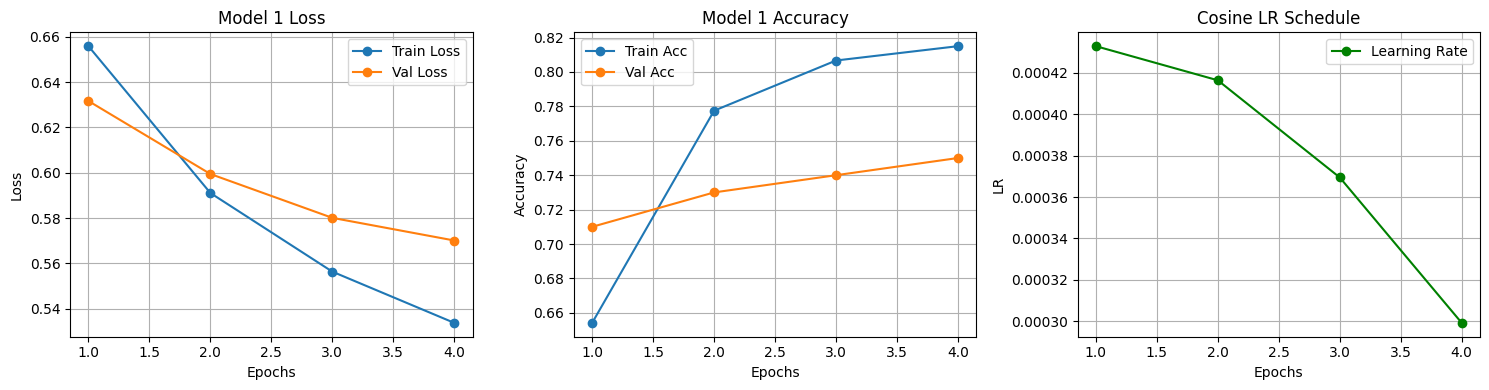

In [13]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(epochs_range, history["train_loss"], label="Train Loss", marker="o")
plt.plot(epochs_range, history["val_loss"], label="Val Loss", marker="o")
plt.title("Model 1 Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(epochs_range, history["train_acc"], label="Train Acc", marker="o")
plt.plot(epochs_range, history["val_acc"], label="Val Acc", marker="o")
plt.title("Model 1 Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(
    epochs_range,
    history.get("lr", [best_params["lr"]] * len(epochs_range)),
    label="Learning Rate",
    color="green",
    marker="o",
)
plt.title("Cosine LR Schedule")
plt.xlabel("Epochs")
plt.ylabel("LR")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

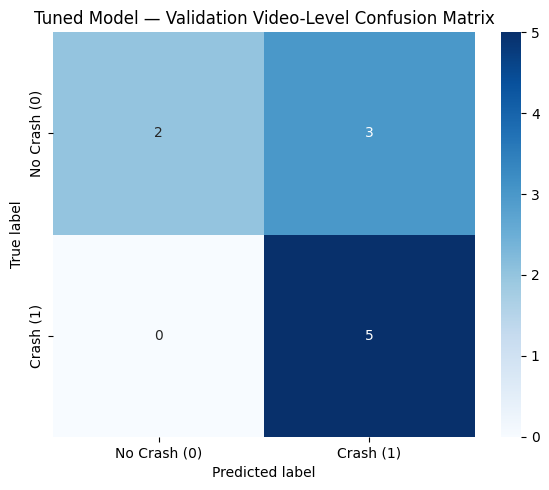

Predictions saved to: ..\outputs\tuned_val_predictions.csv
Evaluation report saved to: ..\outputs\tuned_val_evaluation_report.txt
Confusion matrix saved to: ..\outputs\figures\tuned_video_confusion_matrix.png

Video Macro F1: 0.6703
Video Binary F1: 0.7692
Video Accuracy: 0.7000 (70.00%)

Confusion Matrix:
[[2 3]
 [0 5]]

Classification Report:
              precision    recall  f1-score   support

No Crash (0)     1.0000    0.4000    0.5714         5
   Crash (1)     0.6250    1.0000    0.7692         5

    accuracy                         0.7000        10
   macro avg     0.8125    0.7000    0.6703        10
weighted avg     0.8125    0.7000    0.6703        10



In [14]:
from sklearn.metrics import accuracy_score

OUTPUTS_DIR = Path("../outputs")
FIGURES_DIR = OUTPUTS_DIR / "figures"

OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

model_1_tuned.eval()
val_records = []

with torch.no_grad():
    for images, labels, video_ids in val_loader:
        images = images.to(device)

        logits = model_1_tuned(images).squeeze(1)
        probs = torch.sigmoid(logits).cpu().numpy()

        labels = labels.cpu().numpy()
        val_records.extend(zip(video_ids, labels, probs))

df_val_frames = pd.DataFrame(
    val_records,
    columns=["video_id", "true_label", "prob"],
)

val_video_preds = (
    df_val_frames.groupby("video_id")
    .agg(
        true_label=("true_label", "first"),
        prob=("prob", lambda s: top_k_mean(s, k=5)),
    )
    .reset_index()
)

val_video_preds["id"] = val_video_preds["video_id"].astype(str).str.zfill(5)
val_video_preds["true_label"] = val_video_preds["true_label"].astype(int)
val_video_preds["pred_label"] = (val_video_preds["prob"] >= 0.5).astype(int)

y_true = val_video_preds["true_label"]
y_pred = val_video_preds["pred_label"]

macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
binary_f1 = f1_score(y_true, y_pred, average="binary", zero_division=0)
acc = accuracy_score(y_true, y_pred)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
clf_report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["No Crash (0)", "Crash (1)"],
    digits=4,
    zero_division=0,
)

val_pred_path = OUTPUTS_DIR / "tuned_val_predictions.csv"
val_video_preds[["id", "true_label", "pred_label", "prob"]].to_csv(
    val_pred_path, index=False
)

report_path = OUTPUTS_DIR / "tuned_val_evaluation_report.txt"

with open(report_path, "w", encoding="utf-8") as f:
    f.write("TUNED MODEL — VALIDATION VIDEO-LEVEL EVALUATION\n")
    f.write("=" * 52 + "\n")
    f.write(f"Number of videos: {len(val_video_preds)}\n")
    f.write("Pooling: top_k_mean(k=5)\n")
    f.write("Threshold: 0.5\n\n")
    f.write(f"Macro F1 : {macro_f1:.4f}\n")
    f.write(f"Binary F1: {binary_f1:.4f}\n")
    f.write(f"Accuracy : {acc:.4f} ({acc * 100:.2f}%)\n\n")
    f.write("Confusion Matrix (rows=true, columns=predicted; labels=[0, 1]):\n")
    f.write(f"{cm}\n\n")
    f.write("Classification Report:\n")
    f.write(clf_report)

cm_path = FIGURES_DIR / "tuned_video_confusion_matrix.png"

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Crash (0)", "Crash (1)"],
    yticklabels=["No Crash (0)", "Crash (1)"],
)
plt.title("Tuned Model — Validation Video-Level Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"Predictions saved to: {val_pred_path}")
print(f"Evaluation report saved to: {report_path}")
print(f"Confusion matrix saved to: {cm_path}\n")
print(f"Video Macro F1: {macro_f1:.4f}")
print(f"Video Binary F1: {binary_f1:.4f}")
print(f"Video Accuracy: {acc:.4f} ({acc * 100:.2f}%)")
print("\nConfusion Matrix:")
print(cm)
print("\nClassification Report:")
print(clf_report)